In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
fashion_mnist = fetch_openml(
    "Fashion-MNIST",
    version=1,
    as_frame=True
)

X = fashion_mnist.data
y = fashion_mnist.target

X = X.to_numpy()
y = y.to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (70000, 784)
y shape: (70000,)


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (49000, 784) (49000,)
Validation: (10500, 784) (10500,)
Test: (10500, 784) (10500,)


In [4]:
def preprocess_with_scaling(
    train_features,
    val_features,
    test_features,
    variance_ratio,
    scaling_method
):
    if scaling_method == "minmax":
        train_scaled = train_features / 255.0
        val_scaled = val_features / 255.0
        test_scaled = test_features / 255.0

    elif scaling_method == "standard":
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train_features)
        val_scaled = scaler.transform(val_features)
        test_scaled = scaler.transform(test_features)

    pca = PCA(
        n_components=variance_ratio,
        random_state=42
    )

    train_pca = pca.fit_transform(train_scaled)
    val_pca = pca.transform(val_scaled)
    test_pca = pca.transform(test_scaled)

    return train_pca, val_pca, test_pca, pca

In [6]:
X_train_final, X_val_final, X_test_final, pca_final = preprocess_with_scaling(
    X_train,
    X_val,
    X_test,
    variance_ratio=0.95,
    scaling_method="minmax"
)

print("Training PCA shape:", X_train_final.shape)
print("Validation PCA shape:", X_val_final.shape)
print("Testing PCA shape:", X_test_final.shape)
print("Explained variance:", pca_final.explained_variance_ratio_.sum())

Training PCA shape: (49000, 187)
Validation PCA shape: (10500, 187)
Testing PCA shape: (10500, 187)
Explained variance: 0.9500188024226762


In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="manhattan",
    weights="distance",
    n_jobs=-1
)

knn.fit(X_train_final, y_train)

y_val_pred = knn.predict(X_val_final)

validation_accuracy = (y_val_pred == y_val).mean()

print("Validation Accuracy:", validation_accuracy)

Validation Accuracy: 0.8688571428571429


In [11]:
y_test_pred = knn.predict(X_test_final)

print("Test predictions completed.")

Test predictions completed.


In [12]:
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Test Accuracy:", test_accuracy)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.8687619047619047
Test Accuracy: 86.88%


In [14]:
precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_test_pred,
    average=None
)

for i in range(10):
    print(
        f"Class {i}: "
        f"Precision={precision[i]:.4f}, "
        f"Recall={recall[i]:.4f}, "
        f"F1={f1[i]:.4f}, "
        f"Support={support[i]}"
    )

Class 0: Precision=0.7723, Recall=0.8733, F1=0.8197, Support=1002
Class 1: Precision=0.9903, Recall=0.9743, F1=0.9822, Support=1049
Class 2: Precision=0.7676, Recall=0.7875, F1=0.7774, Support=1040
Class 3: Precision=0.9172, Recall=0.8671, F1=0.8915, Support=1061
Class 4: Precision=0.7854, Recall=0.7898, F1=0.7876, Support=1061
Class 5: Precision=0.9959, Recall=0.8786, F1=0.9336, Support=1112
Class 6: Precision=0.6700, Recall=0.6302, F1=0.6495, Support=1060
Class 7: Precision=0.8904, Recall=0.9666, F1=0.9269, Support=1017
Class 8: Precision=0.9807, Recall=0.9583, F1=0.9694, Support=1008
Class 9: Precision=0.9319, Recall=0.9670, F1=0.9491, Support=1090


In [15]:
macro_precision = precision.mean()
macro_recall = recall.mean()
macro_f1 = f1.mean()

print("Macro Precision:", macro_precision)
print("Macro Recall:", macro_recall)
print("Macro F1:", macro_f1)

Macro Precision: 0.8701756926453731
Macro Recall: 0.869260207130837
Macro F1: 0.8686881563289413


In [16]:
y_test_proba = knn.predict_proba(X_test_final)

print("Probability shape:", y_test_proba.shape)

Probability shape: (10500, 10)


In [18]:
macro_auc = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro"
)

print("Macro AUC:", macro_auc)
print("Macro AUC (%):", macro_auc * 100)

Macro AUC: 0.9734974178267827
Macro AUC (%): 97.34974178267827


In [20]:
auc_scores = []

for i, class_name in enumerate(knn.classes_):
    auc_value = roc_auc_score(
        (y_test == class_name).astype(int),
        y_test_proba[:, i]
    )
    
    auc_scores.append(auc_value)
    
    print(f"Class {class_name}: AUC = {auc_value:.4f}")

Class 0: AUC = 0.9729
Class 1: AUC = 0.9942
Class 2: AUC = 0.9558
Class 3: AUC = 0.9770
Class 4: AUC = 0.9581
Class 5: AUC = 0.9840
Class 6: AUC = 0.9155
Class 7: AUC = 0.9939
Class 8: AUC = 0.9896
Class 9: AUC = 0.9940


In [21]:
macro_auc = np.mean(auc_scores)

print(f"Macro AUC: {macro_auc:.4f}")

Macro AUC: 0.9735


In [24]:
print("y_test shape:", y_test.shape)
print("y_test unique:", np.unique(y_test))
print("knn classes:", knn.classes_)

y_test shape: (10500,)
y_test unique: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
knn classes: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']


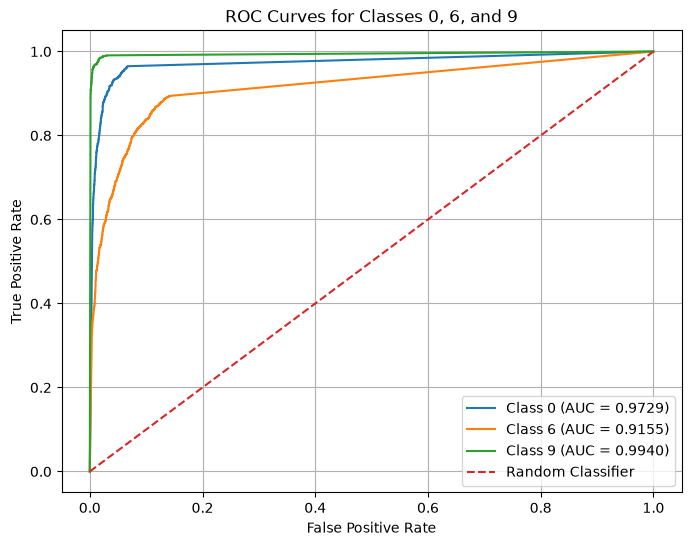

In [25]:
roc_classes = ["0", "6", "9"]

plt.figure(figsize=(8, 6))

for class_name in roc_classes:

    class_index = list(knn.classes_).index(class_name)

    y_true_binary = (y_test == class_name).astype(int)

    y_score = y_test_proba[:, class_index]

    fpr, tpr, _ = roc_curve(y_true_binary, y_score)

    auc_value = roc_auc_score(y_true_binary, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves for Classes 0, 6, and 9")

plt.legend()
plt.grid(True)

plt.show()